## Visual Transformer for Skin Cancer Detection

In [16]:
import evaluate
import torch
from transformers import ViTForImageClassification, Trainer, TrainingArguments
from transformers import ViTImageProcessor
from torchvision.transforms import Compose, Resize, ToTensor, Normalize
import datasets
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import h5py
import cv2
import os
from PIL import Image
from transformers import pipeline
import seaborn as sns
import matplotlib.pyplot as plt
import safetensors.torch
from sklearn.metrics import accuracy_score

In [17]:
MODELS_SAVE_PATH = '../models/'
#BASE_PATH = "../data/isic-2024-challenge"
BASE_PATH = '/projectnb/cs640grp/materials/ISIC-2024_CS640'


In [18]:
file_dict = {
    "sample_sub": "submission.csv",
    "test_images": "test_image",
    "test_metadata": "test_metadata.csv",
    "train_images": "train_image",
    "train_metadata": "train_metadata.csv"
}
for key in file_dict.keys():
    path = os.path.join(os.getcwd(), BASE_PATH, file_dict[key])
    path = os.path.normpath(path)
    file_dict[key] = path
file_dict

{'sample_sub': '/projectnb/cs640grp/materials/ISIC-2024_CS640/submission.csv',
 'test_images': '/projectnb/cs640grp/materials/ISIC-2024_CS640/test_image',
 'test_metadata': '/projectnb/cs640grp/materials/ISIC-2024_CS640/test_metadata.csv',
 'train_images': '/projectnb/cs640grp/materials/ISIC-2024_CS640/train_image',
 'train_metadata': '/projectnb/cs640grp/materials/ISIC-2024_CS640/train_metadata.csv'}

In [19]:

# Train + Valid
df = pd.read_csv(file_dict['train_metadata'])
df = df.ffill()
print("TRAIN SIZE : " , df.shape[0])
display(df.head(2))

# Testing
testing_df = pd.read_csv(file_dict['test_metadata'])
testing_df = testing_df.ffill()
display(testing_df.head(2))

TRAIN SIZE :  320847


,id,target,age_approx,sex,anatom_site_general,clin_size_long_diam_mm,tbp_tile_type,tbp_lv_A,tbp_lv_Aext,tbp_lv_B,...,tbp_lv_norm_color,tbp_lv_perimeterMM,tbp_lv_radial_color_std_max,tbp_lv_stdL,tbp_lv_stdLExt,tbp_lv_symm_2axis,tbp_lv_symm_2axis_angle,tbp_lv_x,tbp_lv_y,tbp_lv_z
0,0,0,55.0,male,upper extremity,2.58,3D: white,21.989610,18.149720,26.138980,...,3.207238,7.162229,1.181736,2.552678,2.169827,0.230000,45,-439.338600,1230.412000,22.647890
1,1,0,50.0,female,posterior torso,2.90,3D: XP,21.153528,17.243578,28.471102,...,2.749542,7.242474,1.014255,2.979940,1.937938,0.292453,65,-59.504822,1047.626465,109.244873


,id,target,age_approx,sex,anatom_site_general,clin_size_long_diam_mm,tbp_tile_type,tbp_lv_A,tbp_lv_Aext,tbp_lv_B,...,tbp_lv_norm_color,tbp_lv_perimeterMM,tbp_lv_radial_color_std_max,tbp_lv_stdL,tbp_lv_stdLExt,tbp_lv_symm_2axis,tbp_lv_symm_2axis_angle,tbp_lv_x,tbp_lv_y,tbp_lv_z
0,0,NaN,30.0,male,upper extremity,2.52,3D: white,20.73976,17.34625,23.60441,...,2.013941,9.113276,0.793600,1.368380,3.130576,0.392593,85,-352.6310,1024.501,21.43127
1,1,NaN,75.0,male,upper extremity,2.63,3D: white,21.49860,17.12805,26.91932,...,3.554856,6.968501,1.322546,2.980941,2.610491,0.342857,150,317.0081,1296.112,85.41052


In [ ]:
#Handle Class Imbalance
print("Class Distribution Before Sampling (%):")
display(df.target.value_counts(normalize=True)*100)

seed = 1 # controllable randomness
neg_sample = .01  
pos_sample = 5.0

# Sampling
positive_df = df.query("target==0").sample(frac=neg_sample, random_state=seed)
negative_df = df.query("target==1").sample(frac=pos_sample, random_state=seed)
df = pd.concat([positive_df, negative_df], axis=0).sample(frac=1.0)

print("\nClass Distribution After Sampling (%):")
display(df.target.value_counts(normalize=True)*100)

# Assume df is your DataFrame and 'target' is the column with class labels
class_weights = compute_class_weight('balanced', classes=np.unique(df['target']), y=df['target'])
class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights)

Class Distribution Before Sampling (%):


target
0    99.902134
1     0.097866
Name: proportion, dtype: float64


Class Distribution After Sampling (%):


target
0    67.120419
1    32.879581
Name: proportion, dtype: float64

Class Weights: {0: 0.7449297971918877, 1: 1.5207006369426752}


In [21]:
from sklearn.model_selection import StratifiedGroupKFold

#training_validation_hdf5 = h5py.File(f"{BASE_PATH}/train-image.hdf5", 'r') # this is gone now since we have a bunch of images

# Reset index to ensure a continuous index
df = df.reset_index(drop=True)
df["fold"] = -1

# Set up the StratifiedGroupKFold with 5 splits
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)

# Assign fold numbers to each data point
for i, (training_idx, validation_idx) in enumerate(sgkf.split(df, y=df.target, groups=df.id)):
    df.loc[validation_idx, "fold"] = int(i)

# Define the train, validation, and test sets
# Use fold 0 for test, fold 1 for validation, and remaining folds for training
training_df = df.query("fold > 1")  # Folds 2, 3, 4 for training
validation_df = df.query("fold == 1")  # Fold 1 for validation
test_df = df.query("fold == 0")  # Fold 0 for testing

# Print the number of samples in each set
print(f"# Num Train: {len(training_df)} | Num Valid: {len(validation_df)} | Num Test: {len(test_df)}")


# Num Train: 2820 | Num Valid: 966 | Num Test: 989


## Augmentation Funcs

In [22]:
# for color jitter
import numpy as np 
import cv2
from pathlib import Path
import random
import torchvision.transforms as transforms 

processor = ViTImageProcessor.from_pretrained('google/vit-base-patch16-224-in21k')

transform = Compose([
        Resize((224, 224)),
        ToTensor(),
        Normalize(mean=processor.image_mean, std=processor.image_std),
    ])

def image_to_byte_string(image_path):
    #useful helper
    image_path = Path(image_path)  
    with image_path.open('rb') as f:
        byte_string = f.read()
    return byte_string


#COLOR JITTER
def colorjitter(img, cj_type="b"):
    '''
    see notebook isic_augmentation for more information of why I chose the specific pvals below. 
    code inspired from : https://towardsdatascience.com/data-augmentation-compilation-with-python-and-opencv-b76b1cd500e0
    '''
    if cj_type == "b":
        transform = transforms.ColorJitter(brightness= .65) 
        img = transform(img)
        return img
    
    elif cj_type == "s":
        transform = transforms.ColorJitter(saturation=.5 )
        img = transform(img)
        return img
    
    elif cj_type == "c":
        transform = transforms.ColorJitter(contrast=.7) 
        img = transform(img)
        return img
    elif cj_type == "h":
        transform = transforms.ColorJitter(hue= .4) 
        img = transform(img)
        return img
def color_transform(ctype = 'b', rand = False):
    #meta function to help during the mapping call 
    if rand: 
        options = ['b','s','c','h']
        ctype = random.choice(options)
    def transform(image):
        return colorjitter(image, cj_type = ctype)
    return transform

# ROTATION
# Inspriation: https://mxnet.apache.org/versions/1.3.1/tutorials/python/types_of_data_augmentation.html
def generate_rotations(image, angle = 0):
    #angle should come from this set : [0, 90, 180, 270]
    rotated_image = image.rotate(angle, expand=True) 
    return rotated_image

def rotation_transform(angle = 0, rand = False):
    #meta function to help during the mapping call 
    if rand: 
        options = [0, 90, 180, 270]
        angle = random.choice(options)
    def transform(image):
        return generate_rotations(image, angle)
    return transform

/share/pkg.8/academic-ml/fall-2024/install/fall-2024-pyt/lib/python3.11/site-packages/huggingface_hub/file_download.py:1150: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [23]:
from datasets import concatenate_datasets

# def preprocess_images_vanilla(example):
#         #Sam's vanilla pre-process code; 999--USE TO DEBUG---999 
#         byte_string = training_validation_hdf5[example["isic_id"]][()]
#         nparr = np.frombuffer(byte_string, np.uint8)
#         image = cv2.imdecode(nparr, cv2.IMREAD_COLOR)[...,::-1]
#         image = Image.fromarray(image)
#         example['pixel_values'] = transform(image)
#         return example
    
def preprocess_images(example, transform_func = None):
        img_path = os.path.join(BASE_PATH, 'train_image', (str(example["id"]) + '.jpg'))
        byte_string = image_to_byte_string(img_path)
        nparr = np.frombuffer(byte_string, np.uint8)
        image = cv2.imdecode(nparr, cv2.IMREAD_COLOR)[...,::-1]
        image = Image.fromarray(image)
        if transform_func != None:
            trans_image = transform_func(image)
            example['pixel_values'] = transform(trans_image)
        else: 
            example['pixel_values'] = transform(image)
        return example

ds_training = datasets.Dataset.from_pandas(pd.DataFrame(data=training_df))
ds_valid = datasets.Dataset.from_pandas(pd.DataFrame(data=validation_df))
ds_test = datasets.Dataset.from_pandas(pd.DataFrame(data=test_df))

subset_ds_training = ds_training

# No Augmentaion
subset_ds_training_o = subset_ds_training.map(preprocess_images, batched=False)
#Rotation Based Augmentation: Equivariance is the principle behind roations
subset_ds_training_r = subset_ds_training.map(lambda example: preprocess_images(example, transform_func=rotation_transform(rand = True)), batched=False)
# ColorJitter Based Augmentation, for each image we do a random sample bc we don't want a huge amount of training data
subset_ds_training_b = subset_ds_training.map(lambda example: preprocess_images(example, transform_func=color_transform(rand = True)), batched=False)


final_ds_training = concatenate_datasets([subset_ds_training_o, subset_ds_training_r, subset_ds_training_b])

# ds_training = ds_training.map(preprocess_images, batched=False)
ds_valid = ds_valid.map(preprocess_images, batched=False)
ds_test = ds_test.map(preprocess_images, batched=False)

Map:   0%|          | 0/2820 [00:00<?, ? examples/s]

Map:   0%|          | 0/2820 [00:00<?, ? examples/s]

Map:   0%|          | 0/2820 [00:00<?, ? examples/s]

Map:   0%|          | 0/966 [00:00<?, ? examples/s]

Map:   0%|          | 0/989 [00:00<?, ? examples/s]

## Statistics of the augemented training dataset

In [24]:
num_examples = len(final_ds_training)
print(f"Examples count: {num_examples}")

Examples count: 8460


In [25]:
#accuracy metric
metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)
     

In [33]:
model_name='google/vit-base-patch16-224-in21k'
processor = ViTImageProcessor.from_pretrained(model_name)
model = ViTForImageClassification.from_pretrained(model_name)

# Make sure its the right tensor types
def collate_fn(batch):
    pixel_values = torch.stack([torch.tensor(example['pixel_values']) for example in batch])
    labels = torch.tensor([example['target'] for example in batch])
    return {'pixel_values': pixel_values, 'labels': labels}

# Define training arguments
training_args = TrainingArguments(
    output_dir='./vit-finetuned-agent_full',
    metric_for_best_model = "accuracy",
    per_device_train_batch_size=128,
    evaluation_strategy="epoch",
    save_strategy="epoch",
    num_train_epochs=20,
    logging_dir='./logs_full',
    logging_steps=10,
    load_best_model_at_end=True,
    remove_unused_columns=False,
    save_total_limit=3, # lets not get too big 
)

# Initialize the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=final_ds_training,
    eval_dataset=ds_valid,
    data_collator=collate_fn,
    tokenizer=processor,
    compute_metrics=compute_metrics
)

Some weights of the model checkpoint at google/vit-base-patch16-224-in21k were not used when initializing ViTForImageClassification: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing ViTForImageClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing ViTForImageClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
#train da model
trainer.train()

# Save da fine-tuned model
trainer.save_model(MODELS_SAVE_PATH + '_aug_full_final')

Epoch,Training Loss,Validation Loss,Accuracy
1,0.168700,0.474716,0.838509
2,0.069200,0.514602,0.846791
3,0.014400,0.670815,0.851967
4,0.012100,0.785572,0.831263
5,0.005100,0.800278,0.841615
6,0.027300,0.583131,0.877847
7,0.019500,0.853222,0.831263
8,0.003300,0.597683,0.881988
9,0.003500,0.597063,0.880952
10,0.002100,0.820856,0.847826


In [35]:
trainer.eval_dataset=ds_test
trainer.evaluate()

{'eval_loss': 0.640713095664978,
 'eval_accuracy': 0.8776541961577351,
 'eval_runtime': 63.4216,
 'eval_samples_per_second': 15.594,
 'eval_steps_per_second': 1.955,
 'epoch': 20.0}

In [37]:
def process_test_set(ds, num_samples):
    inputs = []
    labels = []
    for i in range(num_samples):
        #byte_string = training_validation_hdf5[ds[i]["isic_id"]][()] # SAM PREV LINE
        img_path = os.path.join(BASE_PATH, 'train_image', (str(ds[i]["id"]) + '.jpg'))
        byte_string = image_to_byte_string(img_path)
        nparr = np.frombuffer(byte_string, np.uint8)
        image = cv2.imdecode(nparr, cv2.IMREAD_COLOR)[...,::-1]
        image = Image.fromarray(image)
        inputs.append(image)
        labels.append(ds[i]["target"]) 
    return inputs, labels

inputs, y_true = process_test_set(ds_test, 989)
print(inputs[:10])

[<PIL.Image.Image image mode=RGB size=193x193 at 0x14DCD58EBC90>, <PIL.Image.Image image mode=RGB size=123x123 at 0x14DC97B75210>, <PIL.Image.Image image mode=RGB size=153x153 at 0x14E679599BD0>, <PIL.Image.Image image mode=RGB size=115x115 at 0x14E28CAF0AD0>, <PIL.Image.Image image mode=RGB size=127x127 at 0x14DCD70F1710>, <PIL.Image.Image image mode=RGB size=125x125 at 0x14E1E505B410>, <PIL.Image.Image image mode=RGB size=139x139 at 0x14DCD648AAD0>, <PIL.Image.Image image mode=RGB size=129x129 at 0x14DC9CEEB690>, <PIL.Image.Image image mode=RGB size=159x159 at 0x14DCD9591B90>, <PIL.Image.Image image mode=RGB size=129x129 at 0x14E210932C10>]


## Testing The Model 

In [38]:
model = ViTForImageClassification.from_pretrained(MODELS_SAVE_PATH + '_aug_full_final')
processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224-in21k")

image_classifier = pipeline("image-classification", model,image_processor=processor)
predictions = image_classifier(inputs)
#select highest labels
predictions = [max(item, key=lambda x: x['score'])['label'] for item in predictions]
#convert from LABEL_0, LABEL_1 to 0,1
predictions = [1 if item == 'LABEL_1' else 0 for item in predictions]


/usr4/cs640/rakin374/.local/lib/python3.11/site-packages/transformers/modeling_utils.py:446: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(checkpoint_file,

In [39]:
accuracy = accuracy_score(y_true, predictions)
accuracy

0.8776541961577351

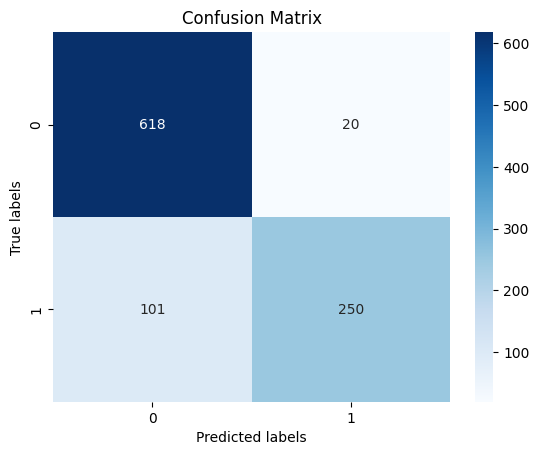

In [40]:
#plot confusion matrix
confusion_metric = evaluate.load("confusion_matrix")
confusion_matrix = confusion_metric.compute(predictions=predictions, references=y_true)
matrix = confusion_matrix['confusion_matrix']
if 'labels' in confusion_matrix:
    labels = confusion_matrix['labels']
else:
    labels = np.unique(predictions + y_true)
sns.heatmap(matrix, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.xlabel("Predicted labels")
plt.ylabel("True labels")
plt.title("Confusion Matrix")
plt.show()